# A slitless grating in a WCC filter slot

The WCC carries one fixed filter per sensor, so a five-band (u, g, r, i, z)
measurement of one target costs four slews. The WCC grating trade study
(G. Fűrész, 2026-11-16) asks what a low-resolution **slitless grating** in place
of one 2.0 mm filter would give instead: a 16-level fused-silica staircase 70 mm
in front of the sensor, 4.414 lines/mm, resolving power $R \approx 20$. The
grating has two halves, each behind an edge coating so that first and second
orders do not overlap:

| Half | Passband | Blaze | Bands | Dispersion |
|---|---|---|---|---|
| `blue` | 350-700 nm (700 nm short-pass) | 430 nm | u, g, r | along pixel rows |
| `red` | 600-1100 nm (600 nm long-pass) | 775 nm | i, z | along pixel columns |

`wcc_etc.GratingSimulation` models one half on one sensor, the Sony IMX455
(`"zwo"`) or the HWK4123 (`"qcmos"`). This notebook covers:

1. the grating efficiency and the end-to-end throughput;
2. the dispersed image of a star, for both halves on both sensors;
3. the SNR per band against magnitude;
4. a comparison with the numbers of the memo.

Not modelled: the 45 nm RMS static wavefront error assumed in the memo (the PSF
here is diffraction-limited with pointing jitter), the FSM smear for bright
hosts, and extended sources.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

import wcc_etc
from wcc_etc import GratingSimulation, get_scene
from wcc_etc.grating import GRATING_HALVES, staircase_efficiency

wcc_etc.set_wcc_style()

SENSORS = {"zwo": "IMX455", "qcmos": "HWK4123"}
HALVES = ["blue", "red"]
BAND_COLORS = {"u": "C4", "g": "C2", "r": "C3", "i": "C1", "z": "k"}


def flat_scene(mag):
    """A source flat in f_nu at AB magnitude `mag`, on V = 22.5 mag/arcsec^2 zodiacal light."""
    return get_scene(
        "flat", mag=mag, bandpass="sdss_r", magsys="abmag",
        background_prop={"bandpass": "johnson_v", "mag": 22.5},
    )


def grating(kind, half, scene):
    return GratingSimulation.from_sensor_and_scene(kind, scene, half=half)

## 1. Efficiency and throughput

`staircase_efficiency` is the scalar diffraction efficiency of an $M$-level
staircase blazed at $\lambda_b$. Each half has its own etch depth, so the first
order peaks near 99% at its blaze wavelength and stays above 50% across the
passband. The zeroth order keeps a few percent of the light in a compact image,
which fixes the position and the wavelength zero point of each source.

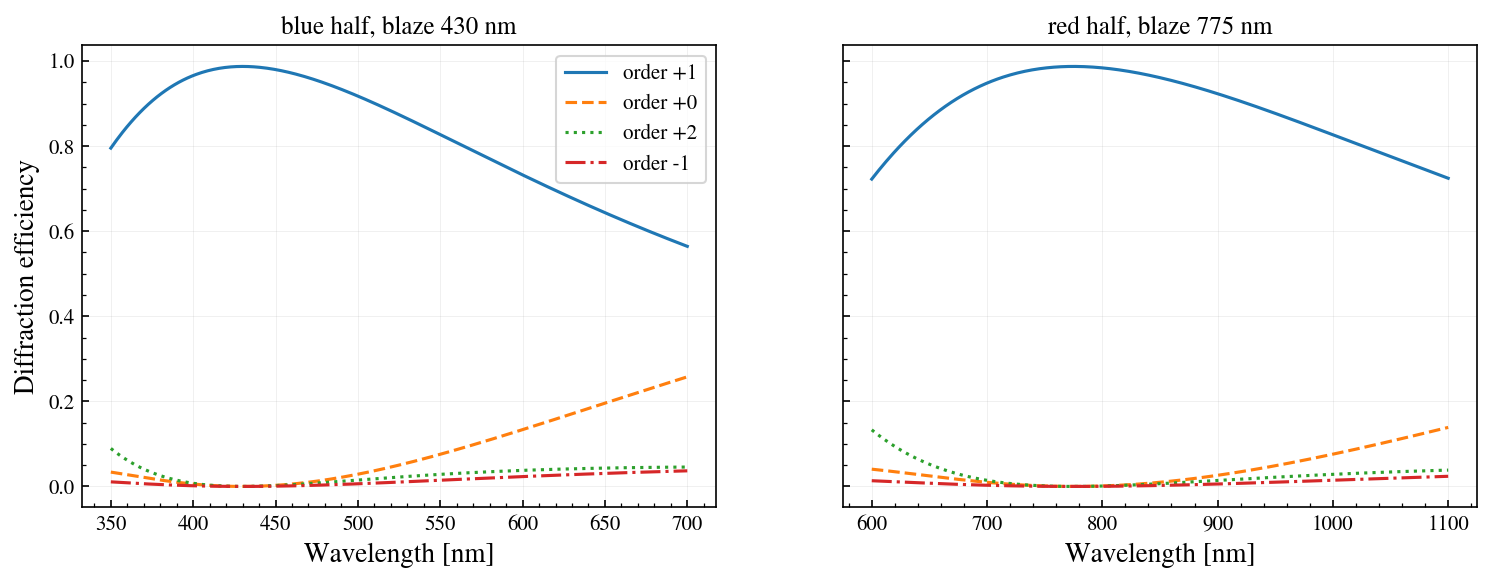

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ranges = {"blue": (350, 700), "red": (600, 1100)}
for ax, half in zip(axes, HALVES):
    wave = np.linspace(*ranges[half], 400)
    blaze = GRATING_HALVES[half]["blaze_nm"]
    for order, ls in [(1, "-"), (0, "--"), (2, ":"), (-1, "-.")]:
        ax.plot(wave, staircase_efficiency(wave, order, blaze), ls, label=f"order {order:+d}")
    ax.set_title(f"{half} half, blaze {blaze:.0f} nm")
    ax.set_xlabel("Wavelength [nm]")
axes[0].set_ylabel("Diffraction efficiency")
axes[0].legend()
plt.show()

The end-to-end throughput of the first order is the `nofilter` sensor curve
(end-of-life telescope, WCC contamination and reserve, detector QE) times the
edge coating (0.95 in band) times the staircase efficiency. The HWK4123 keeps
far more of the red half than the IMX455, and more of the u band.

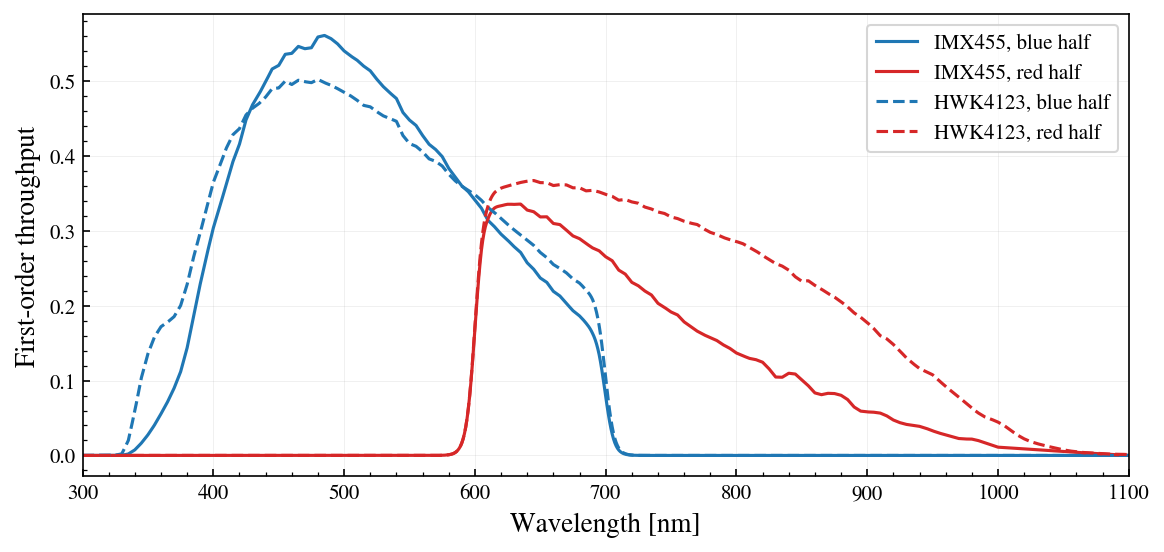

In [3]:
scene = flat_scene(20)
fig, ax = plt.subplots(figsize=(9, 4))
for kind, ls in [("zwo", "-"), ("qcmos", "--")]:
    for half, color in zip(HALVES, ["C0", "C3"]):
        g = grating(kind, half, scene)
        total = g.sim.sensor.bandpass(g.wave_nm * 10).value * g.efficiency(1)
        ax.plot(g.wave_nm, total, ls, color=color, label=f"{SENSORS[kind]}, {half} half")
ax.set_xlabel("Wavelength [nm]")
ax.set_ylabel("First-order throughput")
ax.set_xlim(300, 1100)
ax.legend()
plt.show()

## 2. The dispersed image

Every star becomes a zeroth-order image plus a short spectrum. The first order
of wavelength $\lambda$ lands `offset_px(wavelength)` pixels from the zeroth
order. The same grating gives a shorter trace in pixels on the HWK4123, whose
pixels are 4.6 µm against 3.76 µm.

In [4]:
star = get_scene("G2V", mag=12, bandpass="johnson_v")
for kind in SENSORS:
    g = grating(kind, "blue", star)
    print(
        f"{SENSORS[kind]:8s} R = {g.resolving_power:.1f}, {g.dispersion_px_per_nm:.4f} px/nm, "
        f"first order 350-700 nm at {g.offset_px(350):.1f}-{g.offset_px(700):.1f} px, "
        f"plate scale {g.plate_scale_mas:.1f} mas/px"
    )

IMX455   R = 20.0, 0.0822 px/nm, first order 350-700 nm at 28.8-57.5 px, plate scale 16.9 mas/px
HWK4123  R = 20.0, 0.0672 px/nm, first order 350-700 nm at 23.5-47.0 px, plate scale 20.6 mas/px


`simulate` returns a `SimulatedImage` with orders -1 to +2: a 1 s frame of a
V = 12 G2V star. The blue half disperses along rows and the red half along
columns, as in the baseline layout of the memo. In the blue half the second
order starts where the first order ends; in the red half there is a gap.

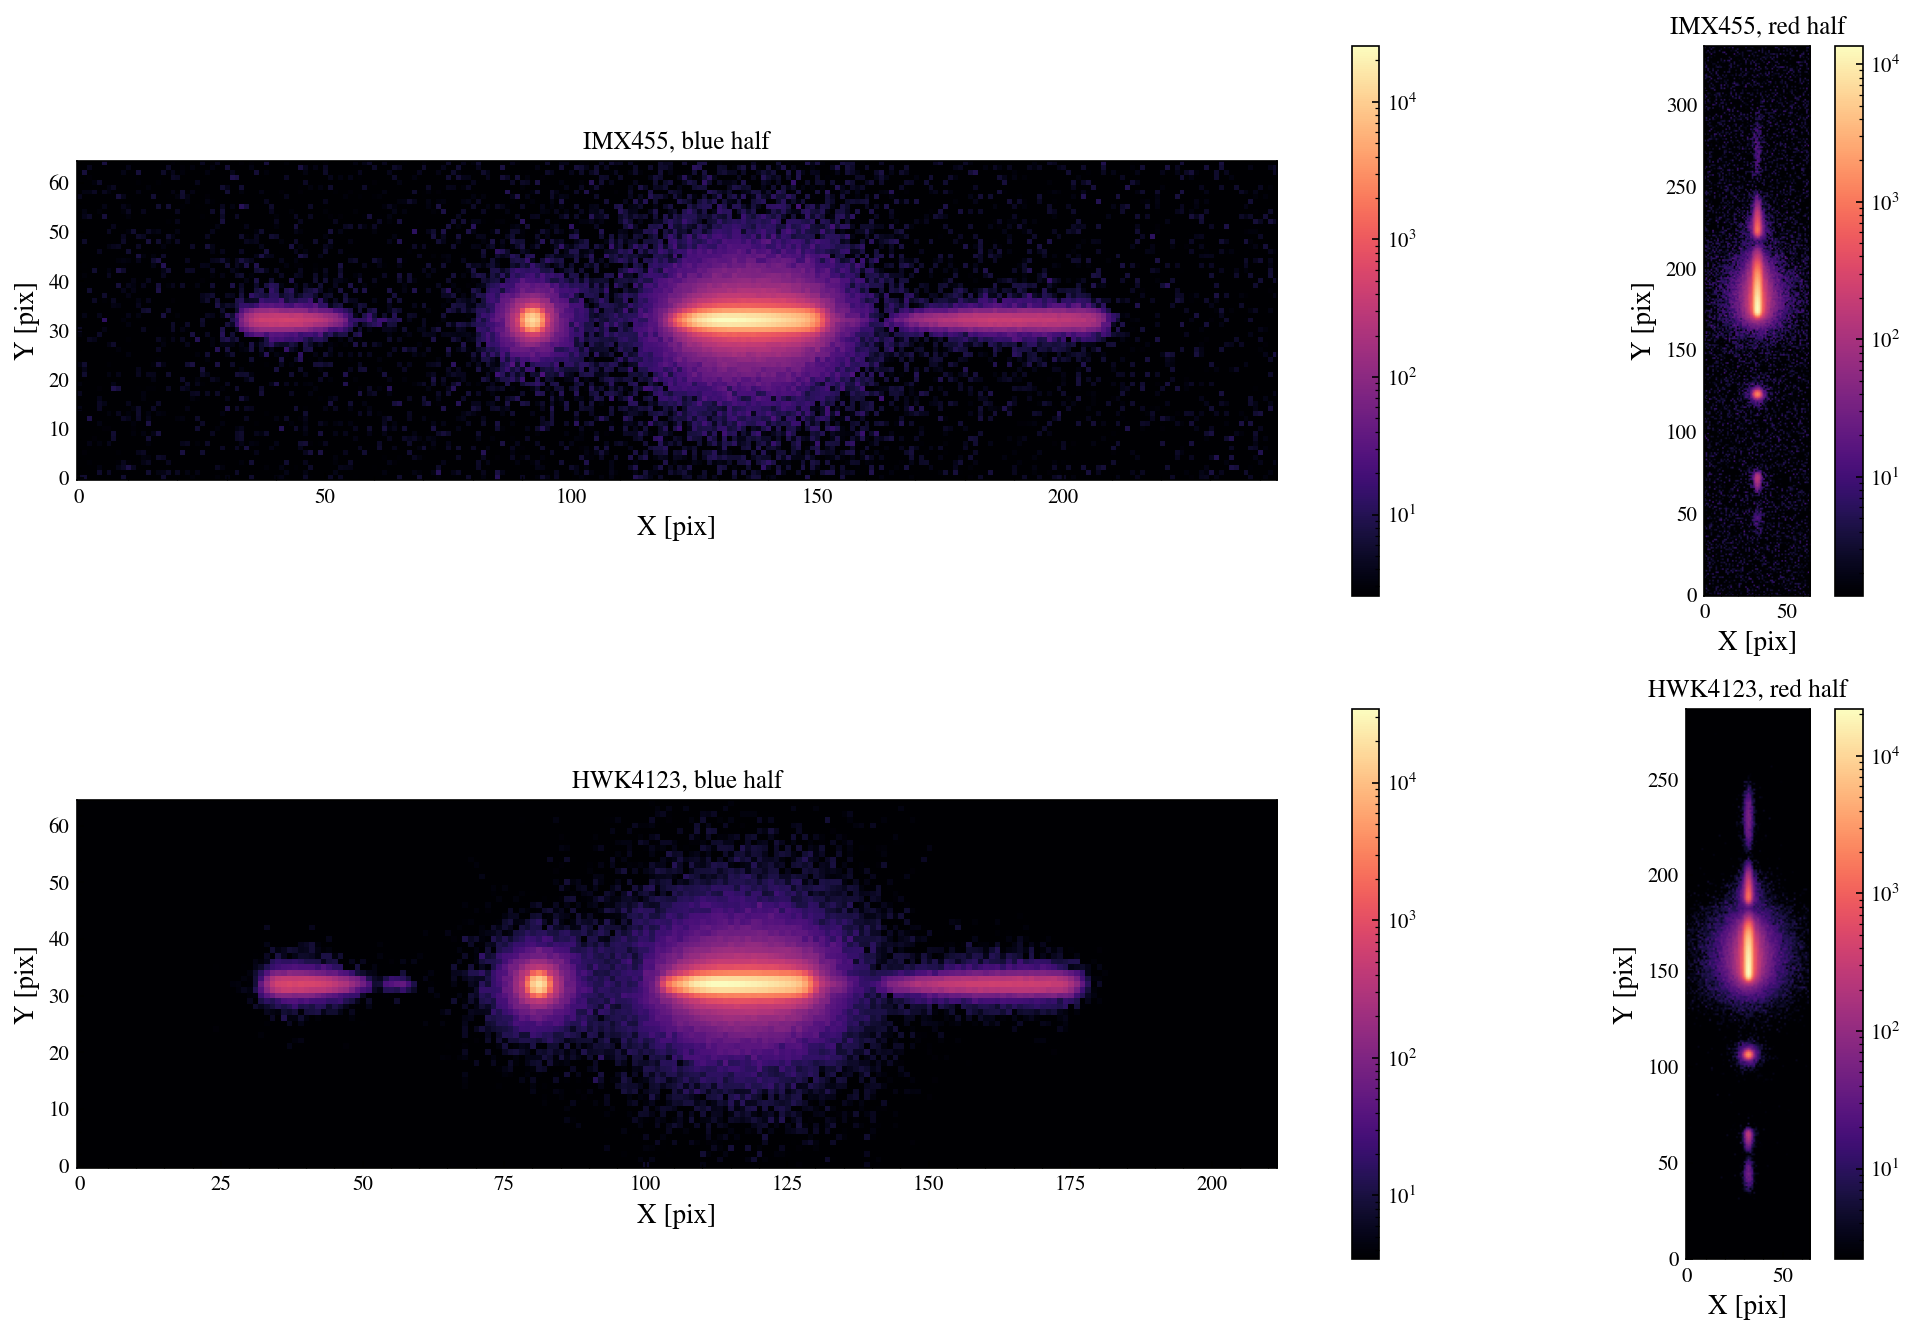

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), gridspec_kw={"width_ratios": [3, 1]})
for row, kind in zip(axes, SENSORS):
    for ax, half in zip(row, HALVES):
        image = grating(kind, half, star).simulate(1.0, seed=1)
        image.plot_image(ax=ax, cmap="magma")
        ax.set_title(f"{SENSORS[kind]}, {half} half")
fig.tight_layout()
plt.show()

Summing the noiseless image across the dispersion gives the spectrum as the
detector sees it. The top axis marks the first-order wavelength.

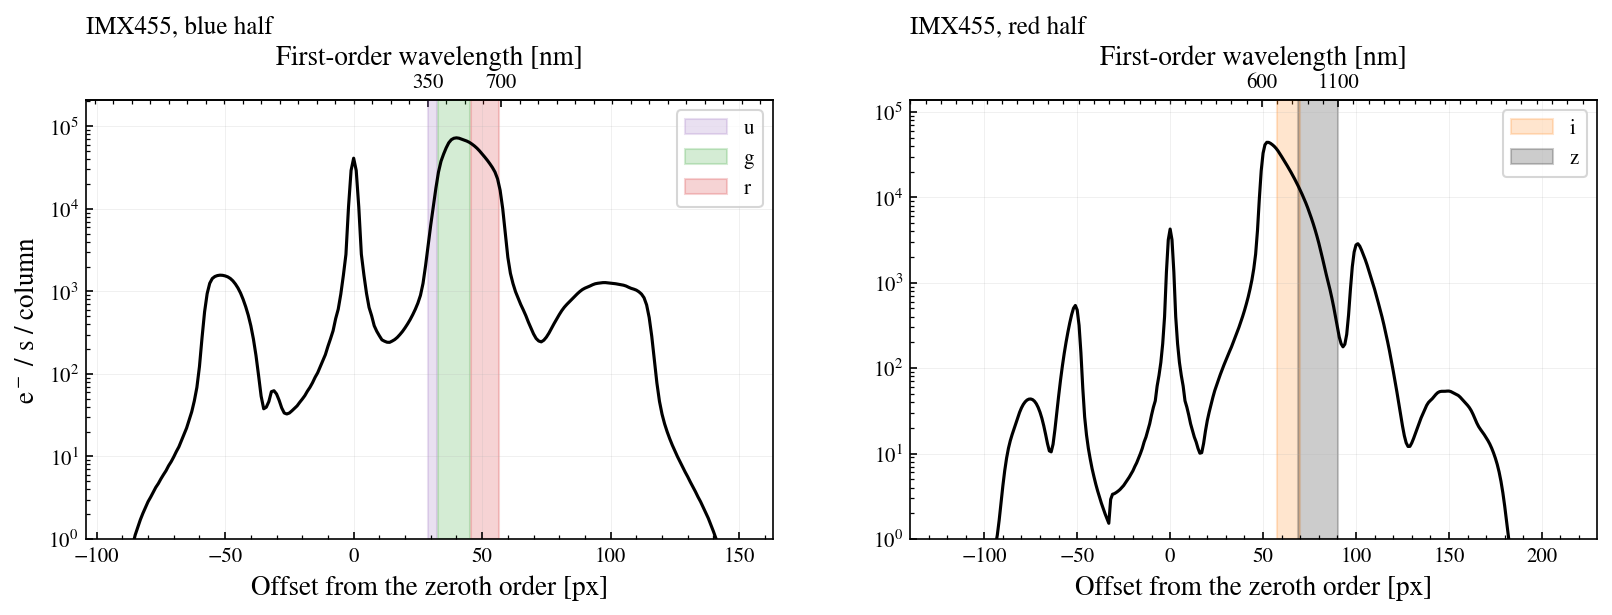

In [6]:
TICKS_NM = {"blue": [350, 700], "red": [600, 1100]}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, half in zip(axes, HALVES):
    g = grating("zwo", half, star)
    _, nx, x0, _ = g.canvas()
    ax.semilogy(np.arange(nx) - x0, g.rate_image().sum(axis=0), color="k")
    for band, (lo, hi) in g.design["bands"].items():
        ax.axvspan(g.offset_px(lo), g.offset_px(hi), color=BAND_COLORS[band], alpha=0.2, label=band)
    top = ax.secondary_xaxis(
        "top", functions=(lambda x, g=g: x / g.dispersion_px_per_nm, lambda w, g=g: w * g.dispersion_px_per_nm)
    )
    top.set_xticks(TICKS_NM[half])
    top.set_xlabel("First-order wavelength [nm]")
    ax.set_xlabel("Offset from the zeroth order [px]")
    ax.set_ylim(1, None)
    ax.set_title(f"IMX455, {half} half", loc="left")
    ax.legend()
axes[0].set_ylabel("e$^-$ / s / column")
plt.show()

## 3. SNR per band against magnitude

`get_band_snr` sums each band in a box of 70 mas either side of the trace by
the length of the band along the first order (the shaded spans above). The
signal is the first-order light in the box; the noise adds the other orders,
the zodiacal light of the whole passband, the dark current and the read noise.

Here each half is exposed for 150 s in 3 reads (a 300 s visit in total), for a
source flat in $f_\nu$. The curves ignore saturation: `get_band_snr` warns when
the brightest pixel of a 50 s frame fills the well, which happens at the bright
end, where shorter frames are needed (see the bright hosts below).

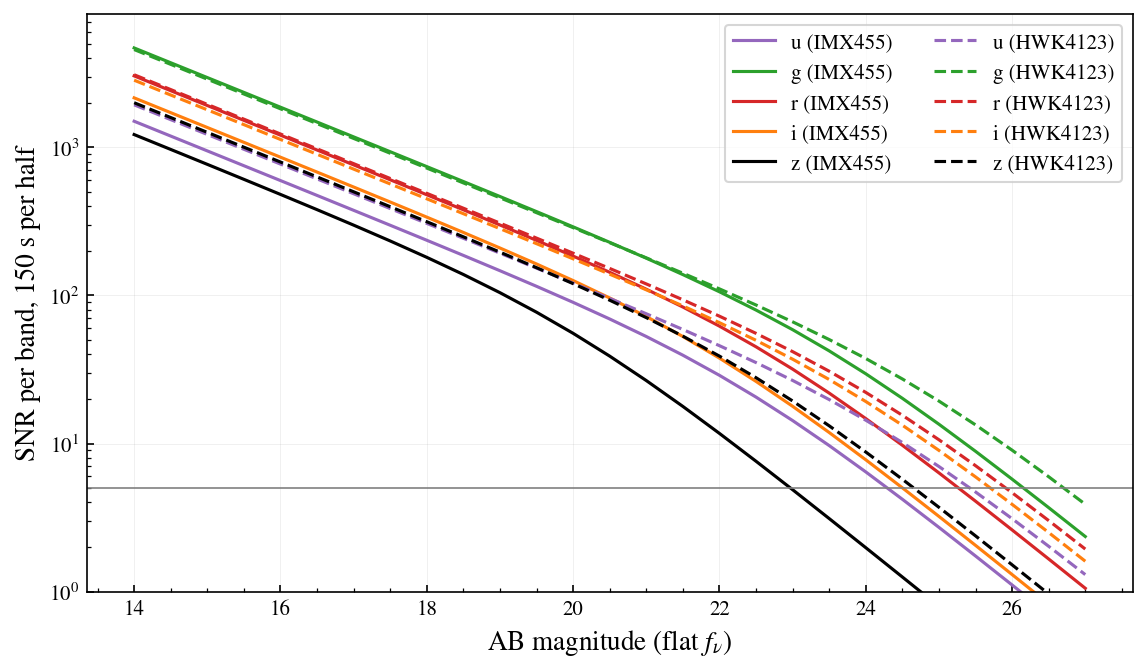

In [7]:
TIME, N_READS = 150.0, 3
MAGS = np.arange(14, 27.01, 0.5)

snr = {}  # (kind, band) -> SNR at each magnitude
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # get_band_snr warns when the brightest pixel saturates
    for kind in SENSORS:
        for half in HALVES:
            rows = [grating(kind, half, flat_scene(m)).get_band_snr(TIME, n_reads=N_READS) for m in MAGS]
            for band in rows[0]:
                snr[kind, band] = np.array([row[band] for row in rows])

fig, ax = plt.subplots(figsize=(9, 5))
for (kind, band), values in snr.items():
    ax.semilogy(
        MAGS, values, "-" if kind == "zwo" else "--", color=BAND_COLORS[band],
        label=f"{band} ({SENSORS[kind]})",
    )
ax.axhline(5, color="0.5", lw=0.8)
ax.set_xlabel("AB magnitude (flat $f_\\nu$)")
ax.set_ylabel(f"SNR per band, {TIME:.0f} s per half")
ax.set_ylim(1, None)
ax.legend(ncol=2)
plt.show()

Bright sources are photon-limited and the two sensors agree where their
throughputs do. At the faint end the HWK4123 goes deeper in every band: its
read noise is six times lower, and it has more throughput in u, i and z.

## 4. Comparison with the memo

### Design numbers (memo Table 2)

The mean first-order efficiency is averaged in $\ln\lambda$ over the passband
of each half, without the edge coating.

In [8]:
def log_mean(half, order):
    wave = np.exp(np.linspace(*np.log(ranges[half]), 500))
    return staircase_efficiency(wave, order, GRATING_HALVES[half]["blaze_nm"]).mean()


memo_design = {"blue": (0.845, 0.070, 28.8, 57.5, 0.029), "red": (0.892, 0.035, 49.3, 90.4, 0.016)}
print(f"{'':28s}{'blue: memo':>12s}{'here':>8s}{'red: memo':>12s}{'here':>8s}")
here = {}
for half in HALVES:
    g = grating("zwo", half, flat_scene(20))
    lo, hi = ranges[half]
    here[half] = (log_mean(half, 1), log_mean(half, 0), g.offset_px(lo), g.offset_px(hi), g.background_rate_per_pix())
labels = ["mean +1 efficiency", "mean zeroth order", "first order starts [px]", "first order ends [px]", "zodi [e-/s/px]"]
for i, label in enumerate(labels):
    b, r = memo_design["blue"][i], here["blue"][i]
    print(f"{label:28s}{b:12.3g}{r:8.3g}{memo_design['red'][i]:12.3g}{here['red'][i]:8.3g}")

for half in HALVES:
    assert np.allclose(here[half], memo_design[half], rtol=0.04)

                              blue: memo    here   red: memo    here
mean +1 efficiency                 0.845   0.846       0.892   0.892
mean zeroth order                   0.07  0.0692       0.035  0.0344
first order starts [px]             28.8    28.8        49.3    49.3
first order ends [px]               57.5    57.5        90.4    90.4
zodi [e-/s/px]                     0.029  0.0293       0.016  0.0165


### Limiting magnitudes (memo Table 3)

The 5σ limit for 300 s of open shutter, 150 s per half, read out the memo's
way (one read per 60 s, so 3 reads). The limit is read off the curves of
section 3.

In [9]:
def limiting_mag(kind, band, threshold=5.0):
    """Magnitude where the SNR curve of section 3 crosses `threshold`."""
    return np.interp(-np.log(threshold), -np.log(snr[kind, band]), MAGS)


memo_limit = {"u": 24.00, "g": 26.07, "r": 25.21, "i": 24.44, "z": 22.90}
print(f"{'band':6s}{'memo':>8s}{'IMX455':>8s}{'diff':>7s}{'HWK4123':>9s}")
for band, memo in memo_limit.items():
    imx, hwk = limiting_mag("zwo", band), limiting_mag("qcmos", band)
    print(f"{band:6s}{memo:8.2f}{imx:8.2f}{imx - memo:+7.2f}{hwk:9.2f}")
    assert 0 < imx - memo < 0.4

band      memo  IMX455   diff  HWK4123
u        24.00   24.30  +0.30    25.42
g        26.07   26.16  +0.09    26.71
r        25.21   25.27  +0.06    25.91
i        24.44   24.50  +0.06    25.70
z        22.90   22.97  +0.07    24.66


The IMX455 limits are 0.06-0.30 mag deeper than the memo's. That is the
expected sign and size: the memo's PSF carries 45 nm RMS of static wavefront
error, which costs every band 0.1-0.4 mag (most in u, where the Strehl ratio is
lowest), and its dark current is taken at +5 °C against 0 °C in the sensor
configuration here. The memo has no HWK4123 numbers; they are new.

### Time to SNR = 10 in all five bands (memo Table 4)

Each half is exposed until its slowest band reaches SNR = 10, with one read per
60 s, and the two halves are switched with a 10 s FSM move.

In [10]:
def time_for_snr(g, target=10.0, max_frame=60.0):
    """Exposure (s) until the slowest band of a half reaches `target`, one read per `max_frame`."""
    n_reads = 1
    for _ in range(20):
        t = max(g.get_band_exptime_for_snr(target, n_reads=n_reads).values())
        needed = max(1, int(np.ceil(t / max_frame)))
        if needed == n_reads:
            break
        n_reads = needed
    return t


memo_clock = {16: 0.17, 20: 0.48, 23: 14.1}
print(f"{'AB':4s}{'memo [min]':>12s}{'IMX455':>9s}{'HWK4123':>9s}")
clock = {}
for mag, memo in memo_clock.items():
    for kind in SENSORS:
        exposure = sum(time_for_snr(grating(kind, half, flat_scene(mag))) for half in HALVES)
        clock[kind, mag] = (exposure + 10.0) / 60.0
    print(f"{mag:<4d}{memo:12.2f}{clock['zwo', mag]:9.2f}{clock['qcmos', mag]:9.2f}")
    assert 0.7 < clock["zwo", mag] / memo < 1.05

AB    memo [min]   IMX455  HWK4123


16          0.17     0.17     0.17


20          0.48     0.43     0.21


23         14.10    10.99     1.19


The same or faster than the memo, for the same reason: at AB = 23 the exposure
is background- and read-noise-limited, where the time scales as the inverse
square of the energy in the box, so the wavefront error costs the most there.
The red half sets the time through the z band, and the HWK4123, with more red
throughput and lower read noise, is much faster.

### Bright hosts (memo Section 7.1)

The memo quotes the time for the brightest pixel of a V = 9 G2V host to fill the
16 275 e$^-$ well of the IMX455: 40 ms (blue half) and 80 ms (red half) without
the wavefront error. `get_peak_pixel` gives the charge per frame.

In [11]:
host = get_scene("G2V", mag=9, bandpass="johnson_v")
memo_full_well_ms = {"blue": 40, "red": 80}
for half in HALVES:
    g = grating("zwo", half, host)
    well = g.sim.sensor.saturation_e.value
    t_full = well / g.get_peak_pixel(1.0).value * 1e3
    print(f"{half:5s} half: full well ({well:.0f} e-) in {t_full:.0f} ms; memo {memo_full_well_ms[half]} ms")
    assert abs(t_full / memo_full_well_ms[half] - 1) < 0.1
    assert g.is_saturated(1.0) and not g.is_saturated(0.01)

blue  half: full well (16275 e-) in 40 ms; memo 40 ms
red   half: full well (16275 e-) in 76 ms; memo 80 ms


## Summary

- `GratingSimulation.from_sensor_and_scene(kind, scene, half=...)` builds one
  half (`"blue"`: u, g, r; `"red"`: i, z) on the IMX455 (`"zwo"`) or the
  HWK4123 (`"qcmos"`).
- `simulate` gives the dispersed frame with the zeroth, first and neighbouring
  orders; `get_peak_pixel` and `is_saturated` work per frame.
- `get_band_snr` and `get_band_exptime_for_snr` return one number per band from
  a box along the first order.
- The design numbers, zodiacal rates and bright-host saturation times match the
  memo; limiting magnitudes are 0.06-0.30 mag deeper because the PSF here has no
  static wavefront error. Pass `psf=` to `GratingSimulation` to supply one.